[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anita-agasaveeran/Assignment4/blob/main/03_KDD_Canada_Electricity/notebooks/KDD_Canada_Electricity.ipynb)

# Is Canada's Grid Becoming Less Combustion-Dependent? Knowledge Discovery in Canadian Electricity Data
**CMPE 255 · Assignment 4 · Project 3 of 3**

This project follows the **KDD process** (Fayyad, Piatetsky-Shapiro & Smyth, 1996): domain understanding and goals → **Selection** → **Preprocessing** → **Transformation** → **Data mining** → **Interpretation / evaluation** → using the knowledge. A **front pass** first checks the data, fixes the preprocessing rules and freezes the holdouts.

*Data: [Canada Electricity: Generation and Trade](https://www.kaggle.com/datasets/hgultekin/canada-monthly-electricity-benchmark) (Habib Gultekin, 2026). Adapted from Statistics Canada, Tables 25-10-0015-01 and 25-10-0016-01 (reference periods 2008-01 to 2026-08), Statistics Canada Open Licence. This does not constitute an endorsement by Statistics Canada.*

## 0. Setup

In [1]:
import os, subprocess, sys
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/anita-agasaveeran/Assignment4.git"
if IN_COLAB:
    if not Path("/content/Assignment4").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/Assignment4"], check=True)
    PROJECT_DIR = Path("/content/Assignment4/03_KDD_Canada_Electricity")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "/content/Assignment4/requirements.txt"], check=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_DIR / "src")); os.chdir(PROJECT_DIR)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from kddenergy import config as c
from kddenergy.data import load_generation, load_availability, load_backtest, generation_wide, thermal_series
c.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
ATTRIBUTION = "Source: adapted from Statistics Canada, Tables 25-10-0015-01 and 25-10-0016-01. This does not constitute an endorsement by Statistics Canada."
print("Project dir:", PROJECT_DIR, "| pandas", pd.__version__)

Project dir: /Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/03_KDD_Canada_Electricity | pandas 3.1.0


---
# Front pass · Goals, data checks, preprocessing rules, frozen holdouts

> **Revision 2**, after critic round 1 (6/10; `critiques/frontpass_round1.md`). Main changes:
> - the 2016 break is now treated as a **reporting-coverage expansion**, with a frozen "2016+ only" rule;
> - K2 is reframed from "thermal share" to **non-emitting / combustion share**;
> - the first lead is restated on development data only;
> - the loaders enforce the seal;
> - per-goal acceptance rules and the K4 margin are pre-registered.

### F.1 Domain and goals (KDD step 0)
**Hypothetical audience:** energy analysts and policy staff who want evidence about how Canada's provincial power systems differ and change.

| Goal | Question | Pre-registered acceptance (validity) |
|---|---|---|
| K1 Archetypes | Which provinces behave alike (generation mix, seasonality, trade dependence)? | Cluster assignments from 2016–2024 features vs 2025–26 features: adjusted Rand index ≥ 0.7 (`config.K1_MIN_ARI`) |
| K2 Structural change | When did each province's **non-emitting share** (hydro + nuclear + wind + solar + tidal) or **combustion share** change? Did the grid get *less combustion-dependent*? | A change point found on 2016–2024 data at **province level**: post-change direction persists in 2025–26, and the date is stable to ±3 months under resampling |
| K3 Anomalies | Which months were unusual (droughts, cold snaps, outages)? | Precision ≥ 0.5 of flagged months against an **event catalogue compiled from public sources before mining** |
| K4 Prediction | Can monthly availability be forecast better than seasonal naive? | Pooled WAPE on the sealed origins ≤ 0.90 × seasonal naive **and** better at both sealed origins |

**What "cleaner" can and can't mean here.** The data measures *sources* of generation, not emissions. A coal-to-gas switch, as in Alberta, cuts emissions without changing the combustion share. So K2 answers "less combustion-dependent?", and **emissions intensity is out of scope** unless external data (e.g. ECCC's National Inventory Report) is added. *Novelty* is judged against a named baseline, the Canada Energy Regulator's provincial energy profiles. *Usefulness* and *understandability* mean one chart and one sentence per finding.

### F.2 Data checks

*Structural checks (counts, status codes, additivity) use the full table, because they describe how the data is built, not what it says. Every value analysis after this uses data through 2024-12 only (sealed loaders).*

In [2]:
gen_all, avail_all = load_generation(allow_sealed=True), load_availability(allow_sealed=True)   # structure only
w_all = generation_wide(gen_all)
display(gen_all["source_status"].fillna("observed").value_counts().to_frame("status codes"))
tot_all = w_all[c.TOTAL_GEN].unstack("geography"); prov = tot_all.drop(columns="Canada"); full = prov.notna().all(axis=1)
print(f"Canada total = sum of provinces on all {full.sum()} complete months: {np.allclose(prov[full].sum(axis=1), tot_all.loc[full, 'Canada'])}")
cls = gen_all.pivot_table(index=["geography", "month", "generation_type"], columns="producer_class", values="generation_mwh")
both = cls.dropna()   # cells where utilities, industries and all-producers are all observed
print(f"utilities + industries = all producers on {len(both):,} fully observed cells: "
      f"{np.allclose(both.iloc[:, 0] + both.iloc[:, 1], both[c.TOTAL_PRODUCERS])}")
th_all = thermal_series(w_all)
ref = w_all[c.THERMAL_TECH_2008_2015].sum(axis=1, min_count=1).fillna(w_all[c.THERMAL_FUEL_2016_ON])
diff = (th_all - ref).dropna()
print(f"thermal residual vs StatCan thermal categories: {(diff.abs() <= 1).mean():.2%} of geo-months within 1 MWh; max |diff| = {diff.abs().max():,.0f} MWh")
exc = diff[diff.abs() > 1]
sealed_exc = exc[exc.index.get_level_values("month") > c.DISCOVERY_END]
display(exc[exc.index.get_level_values("month") <= c.DISCOVERY_END].rename("residual - reported (MWh)").to_frame())
print(f"(+ {len(sealed_exc)} exception(s) in sealed months, counted but not shown)")
neg = gen_all[gen_all["generation_mwh"] < 0]
print(f"negative generation values: {len(neg)} (net generation, e.g. station service during outages)")
display(neg.groupby(["geography", "generation_type"]).size().sort_values(ascending=False).head(6).to_frame("rows"))
print("availability balance residual != 0:", avail_all.loc[avail_all.balance_residual_mwh.abs() > 0, ["month", "geography", "balance_residual_mwh"]].to_dict("records"))

,status codes
source_status,
observed,58707
..,17955
x,114


Canada total = sum of provinces on all 224 complete months: True
utilities + industries = all producers on 15,483 fully observed cells: True
thermal residual vs StatCan thermal categories: 99.74% of geo-months within 1 MWh; max |diff| = 4,000 MWh


residual - reported (MWh)
geography     month                             
Alberta       2008-11                     4000.0
Canada        2008-11                     4000.0
              2015-07                      -14.0
              2022-03                     -300.0
New Brunswick 2015-07                      -12.0
Ontario       2022-03                     -300.0

(+ 2 exception(s) in sealed months, counted but not shown)
negative generation values: 652 (net generation, e.g. station service during outages)


rows
geography            generation_type                  
Prince Edward Island Conventional steam turbine    128
New Brunswick        Nuclear steam turbine         108
Prince Edward Island Combustion turbine            102
New Brunswick        Internal combustion turbine    70
Quebec               Combustion turbine             58
                     Nuclear steam turbine          46

availability balance residual != 0: [{'month': '2019-02', 'geography': 'British Columbia', 'balance_residual_mwh': 70931.0}, {'month': '2019-02', 'geography': 'Canada', 'balance_residual_mwh': 70931.0}, {'month': '2019-10', 'geography': 'Canada', 'balance_residual_mwh': -1.0}]


**What this shows:**
- **The totals add up.** Canada = Σ provinces (224/224 months); utilities + industries = all producers.
- **The thermal residual matches StatCan's reported thermal categories** within 1 MWh on all but 8 geo-months (max |diff| 4,000 MWh, in Alberta Nov 2008). They're kept; the development-period ones are listed and the 2 sealed-month ones only counted.
- **652 negative values are net generation** (e.g. station service at New Brunswick's Point Lepreau nuclear plant during its 2008–2012 refurbishment). They're kept as net generation, a Preprocessing decision recorded here.
- **The availability accounting balances** except for the documented Feb 2019 BC residual and a 1 MWh rounding residual.

#### The 2016 break is a reporting-coverage expansion plus a thermal reclassification

In [3]:
g = gen_all.assign(year=gen_all["month"].str[:4].astype(int))
x = g[g["year"].between(2014, 2017) & (g["geography"] != "Canada")]
cov = (x.assign(observed=x["generation_mwh"].notna())
         .groupby(["producer_class", "generation_type", "year"])["observed"].sum().unstack("year"))
cov = cov[cov.diff(axis=1).abs().sum(axis=1) > 0]
cov.index = cov.index.set_levels(cov.index.levels[0].str.replace("Electricity producers, ", "").str.replace("Total all classes of electricity producer", "all producers"), level=0)
display(cov.fillna(0).astype(int).rename_axis(columns="observed province-months"))
yr = w_all[[c.TOTAL_GEN, "Wind power turbine", "Solar"]].groupby([w_all.index.get_level_values(0), w_all.index.get_level_values(1).str[:4]]).sum(min_count=1)
step = (yr.xs("Canada", level=0).loc[["2014", "2015", "2016", "2017"]] / 1e6).round(2)
display(step.rename(columns=lambda s: s + " (TWh)"))
display((yr.xs("Alberta", level=0).loc[["2014", "2015", "2016", "2017"], [c.TOTAL_GEN]] / 1e6).round(1).rename(columns={c.TOTAL_GEN: "Alberta total (TWh)"}))

observed province-months                                               2014  \
producer_class     generation_type                                            
electric utilities Combustion turbine                                   124   
                   Conventional steam turbine                           117   
                   Hydraulic turbine                                    132   
                   Internal combustion turbine                          133   
                   Other types of electricity generation                  0   
                   Solar                                                 12   
                   Tidal power turbine                                   12   
                   Wind power turbine                                   116   
industries         Combustion turbine                                    36   
                   Conventional steam turbine                            96   
                   Hydraulic turbine                                     36   
                   Internal combustion turbine                           47   
                   Other types of electricity generation                  0   
                   Solar                                                  0   
                   Tidal power turbine                                    0   
                   Total all types of electricity generation            120   
                   Total electricity production from combustible f...     0   
                   Wind power turbine                                    12   
all producers      Combustion turbine                                   124   
                   Conventional steam turbine                           120   
                   Hydraulic turbine                                    132   
                   Internal combustion turbine                          144   
                   Other types of electricity generation                  0   
                   Solar                                                 12   
                   Tidal power turbine                                   12   
                   Wind power turbine                                   128   

observed province-months                                               2015  \
producer_class     generation_type                                            
electric utilities Combustion turbine                                   120   
                   Conventional steam turbine                           117   
                   Hydraulic turbine                                    132   
                   Internal combustion turbine                          132   
                   Other types of electricity generation                  0   
                   Solar                                                 12   
                   Tidal power turbine                                   12   
                   Wind power turbine                                   118   
industries         Combustion turbine                                    36   
                   Conventional steam turbine                            96   
                   Hydraulic turbine                                     36   
                   Internal combustion turbine                           38   
                   Other types of electricity generation                  0   
                   Solar                                                  0   
                   Tidal power turbine                                    0   
                   Total all types of electricity generation            120   
                   Total electricity production from combustible f...     0   
                   Wind power turbine                                    12   
all producers      Combustion turbine                                   120   
                   Conventional steam turbine                           123   
                   Hydraulic turbine             

generation_type,Total all types of electricity generation (TWh),Wind power turbine (TWh),Solar (TWh)
month,,,
2014,599.93,8.98,0.25
2015,592.76,8.85,0.26
2016,646.29,30.48,1.79
2017,649.38,30.91,2.05


generation_type,Alberta total (TWh)
month,
2014,65.7
2015,60.6
2016,79.2
2017,81.4


**Conclusion:**
- **What changed.** From January 2016, StatCan's survey reports producers it didn't cover before:
  - industrial wind, solar, tidal and "other" go from ≤ 12 reported province-months a year to 110–122 (some of them published zeros: industrial wind goes from 12 to 64 non-zero, utility solar from 12 to 35);
  - Canada's total generation rises 9% in one year, wind 3.4× and Alberta's total 31%;
  - in 2008–09, Manitoba and New Brunswick totals even exclude their suppressed wind;
  - separately, thermal output was *reclassified* from technology types to fuel types in 2016.
- **So 2008–2015 and 2016+ aren't comparable**, for thermal, wind, solar, totals *and* availability. The residual is additive *within* each era but can't bridge *across* them.
- **Frozen rule (`config.CONSISTENT_START = "2016-01"`):**
  - every cross-year comparison, cluster feature, trend, change point and anomaly baseline uses 2016-01 onward;
  - pre-2016 data is used only within its own era;
  - a 2016 change point is never reported as a discovery.

### F.3 First look at K2 (development data only: 2016-01 → 2024-12)

,non-emitting share,combustion share,non-renewable combustion share,hydro (TWh),nuclear (TWh),wind + solar (TWh)
month,,,,,,
2016,0.788,0.212,NaN,381.406,95.687,32.268
2017,0.800,0.200,NaN,390.753,95.743,32.955
2018,0.796,0.203,NaN,381.639,95.037,34.054
2019,0.794,0.206,NaN,377.641,95.469,35.254
2020,0.809,0.191,0.177,382.616,92.652,38.832
2021,0.802,0.198,0.183,376.987,87.376,38.921
2022,0.808,0.192,0.179,392.353,82.301,42.275
2023,0.793,0.206,0.191,359.286,84.566,44.325
2024,0.779,0.221,0.205,341.824,81.735,51.077


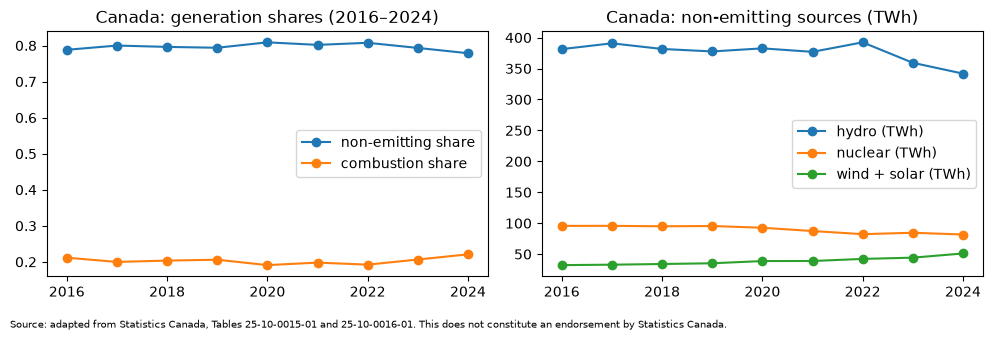

In [4]:
gen = load_generation()            # sealed: months <= 2024-12
w = generation_wide(gen)
can = w.xs("Canada", level="geography")
can = can[can.index >= c.CONSISTENT_START]
yearly = can.groupby(can.index.str[:4]).sum(min_count=1)
view = pd.DataFrame({
    "non-emitting share": yearly[c.NON_EMITTING].sum(axis=1) / yearly[c.TOTAL_GEN],
    "combustion share": thermal_series(w).xs("Canada", level="geography").loc[lambda s: s.index >= c.CONSISTENT_START].groupby(lambda m: m[:4]).sum() / yearly[c.TOTAL_GEN],
    "non-renewable combustion share": yearly["Total electricity production from non-renewable combustible fuels"] / yearly[c.TOTAL_GEN],
    "hydro (TWh)": yearly["Hydraulic turbine"] / 1e6, "nuclear (TWh)": yearly["Nuclear steam turbine"] / 1e6,
    "wind + solar (TWh)": (yearly["Wind power turbine"] + yearly["Solar"]) / 1e6,
})
display(view.round(3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
view[["non-emitting share", "combustion share"]].plot(ax=ax[0], marker="o", title="Canada: generation shares (2016–2024)")
view[["hydro (TWh)", "nuclear (TWh)", "wind + solar (TWh)"]].plot(ax=ax[1], marker="o", title="Canada: non-emitting sources (TWh)")
for a in ax: a.set_xlabel("")
fig.text(0.01, -0.04, ATTRIBUTION, fontsize=7)
plt.tight_layout(); plt.savefig(c.FIGURES_DIR / "f_canada_shares_2016_2024.png", dpi=150, bbox_inches="tight"); plt.show()

**The lead, restated (development data only).**
- **The share barely moved, then fell.** Canada's non-emitting share was roughly flat from 2016 to 2022, then fell in 2023–24 (the combustion share rose from about 19% to 22%).
- **What the table actually shows for 2022 → 2024** (corrected after critic round 2):
  - hydro fell 50.5 TWh (Quebec −30.7, BC −10.9, Manitoba −7.3; consistent with drought years in the public record);
  - that was mostly matched by **lower total generation** (−30.6 TWh; Quebec's total fell about as much as its hydro), not by more burning;
  - combustion rose 11.5 TWh, almost all in **Ontario** (+10.2);
  - nuclear was flat over 2022–24 (its decline came in 2020–22, when the share didn't move);
  - wind + solar grew 8.8 TWh.
  - So about half of the combustion-share rise is a shrinking denominator. K2's controls will include total generation and trade, not only hydro and nuclear.
- **The question for K2** is therefore not "did the grid get cleaner?" but: ***is the recent rise in combustion structural, or a hydro/nuclear availability dip that wind and solar can't yet cover?*** That's answered province by province in the KDD steps, with hydro and nuclear availability controlled.

**Disclosure:** the first draft of this front pass showed the *national* annual thermal share for 2025–2026. National-level K2 confirmation on 2025–26 is therefore treated as spent. Because Ontario drives about 90% of the national combustion change, **Ontario's** confirmation is treated as partly spent too and reported separately. The K2 verdict rests on the other provinces.

### F.4 Frozen holdouts (enforced in code)
| Goal | Development | Sealed / confirmation |
|---|---|---|
| K1–K3 | 2016-01 → **2024-12** (the consistent era) | **2025-01 → 2026-08**: patterns must persist (rules in F.1). National thermal/combustion share for 2025–26 already viewed (disclosed) |
| K4 | Forecast origins Dec 2018 → Dec 2023 (the dataset's own backtest design, 12-month horizon) | **Origins Dec 2024 and Dec 2025**, scored once |

- **How the seal is enforced:** `load_generation()`, `load_flows()` and `load_availability()` drop months after 2024-12 unless called with `allow_sealed=True`, and `load_backtest()` drops the sealed origins. Tests check this.
- **The dataset's published benchmark** (3.30% WAPE in `backtest_metrics.csv`) includes the sealed 2024-12 origin and the Canada aggregate, so it's never quoted.

### F.5 Feasibility for K4 (development origins only)

In [5]:
avail, bt = load_availability(), load_backtest()
A = avail.pivot(index="month", columns="geography", values="availability_mwh"); A.index = pd.PeriodIndex(A.index, freq="M")
geos = [g for g in A.columns if g != "Canada"]
rows = []
for o in c.DEV_ORIGINS:
    op = pd.Period(o, "M"); tgt = pd.period_range(op + 1, op + c.FORECAST_HORIZON, freq="M"); hist = A.loc[:op]
    for g in geos:
        y, h = A.loc[tgt, g], hist[g].dropna()
        if y.isna().any() or len(h) < 36:
            continue
        snaive = np.array([h.get(t - 12, np.nan) for t in tgt])
        avg3 = np.array([np.nanmean([h.get(t - 12 * k, np.nan) for k in (1, 2, 3)]) for t in tgt])
        growth = h.iloc[-12:].sum() / h.iloc[-24:-12].sum()
        rows.append({"origin": o, "geo": g, "y": y.to_numpy(), "snaive": snaive, "avg3": avg3, "avg3_growth": avg3 * np.sqrt(growth)})
# my seasonal naive must equal the dataset's own row-level forecasts (development origins, provinces/territories)
file_sn = bt[(bt.geography != "Canada") & bt.usable_prediction].set_index(["forecast_origin", "geography", "month"])["seasonal_naive_mwh"]
mine = pd.Series({(r["origin"], r["geo"], str(t)): v for r in rows for t, v in zip(pd.period_range(pd.Period(r["origin"], "M") + 1, periods=12, freq="M"), r["snaive"])})
common = mine.index.intersection(file_sn.index)
assert len(common) == len(mine) == len(file_sn), (len(common), len(mine), len(file_sn))
assert np.allclose(mine.loc[common], file_sn.loc[common]), "seasonal naive differs from the dataset's backtest"
print(f"seasonal naive matches the dataset's backtest row by row ({len(common)} forecasts)")
W = lambda rs, k: 100 * sum(np.abs(r["y"] - r[k]).sum() for r in rs) / sum(r["y"].sum() for r in rs)
methods = {"seasonal naive": "snaive", "3-year seasonal mean": "avg3", "3-year mean × √growth": "avg3_growth"}
per_origin = pd.DataFrame({name: {o: W([r for r in rows if r["origin"] == o], k) for o in c.DEV_ORIGINS} for name, k in methods.items()})
per_origin.loc["pooled"] = {name: W(rows, k) for name, k in methods.items()}
display(per_origin.round(2).rename_axis("origin (WAPE %)"))
rng = np.random.default_rng(c.SEED)
ratios = [W(s, "avg3_growth") / W(s, "snaive") for s in ([rows[i] for i in rng.integers(0, len(rows), len(rows))] for _ in range(1000))]
wins = np.mean([np.abs(r["y"] - r["avg3_growth"]).sum() < np.abs(r["y"] - r["snaive"]).sum() for r in rows])
print(f"WAPE ratio (3-year mean × √growth / seasonal naive): {W(rows, 'avg3_growth') / W(rows, 'snaive'):.3f}, "
      f"90% bootstrap interval {np.quantile(ratios, 0.05):.3f}-{np.quantile(ratios, 0.95):.3f}; better on {wins:.0%} of {len(rows)} province-origin pairs")

seasonal naive matches the dataset's backtest row by row (936 forecasts)


,seasonal naive,3-year seasonal mean,3-year mean × √growth
origin (WAPE %),,,
2018-12,3.25,3.34,3.29
2019-12,3.90,3.92,3.93
2020-12,4.24,3.75,3.78
2021-12,4.56,4.49,4.19
2022-12,4.52,3.57,3.65
2023-12,4.03,3.64,3.46
pooled,4.08,3.78,3.71


WAPE ratio (3-year mean × √growth / seasonal naive): 0.910, 90% bootstrap interval 0.862-0.961; better on 69% of 78 province-origin pairs


**Feasibility verdict (K4):**
- **The benchmark is reproduced row by row** (assert). 4.08% is the dataset's seasonal naive on these 6 development origins × 13 provinces and territories; the published 3.30% also includes the sealed origin and the Canada aggregate.
- **A trivial 3-year seasonal mean with a growth adjustment is about 9% better when pooled**, but not at every origin. The bootstrap interval is shown above. So the pre-registered K4 margin (≤ 0.90×, and better at both sealed origins) is a real test, not a formality.
- *Caveat:* the data is StatCan's latest revised vintage, not what was known in real time, so backtests can look slightly better than live forecasting would.
- **K1–K3:** the data supports them within the consistent era (2016–2024: 108 months × 13 geographies), with trade flows by partner available for net-import ratios.

---
# KDD 1 · Selection

- Geographies: 10 provinces + 3 territories (the Canada aggregate kept separate); consistent era 2016-01+
- Non-overlapping generation types; flow components (provincial vs US trade)

In [6]:
# TODO

---
# KDD 2 · Preprocessing

- Status codes → missing; negative values kept as net generation
- Event catalogue for K3 compiled from public sources *before* mining
- Cross-table integration; accounting identity

In [7]:
# TODO

---
# KDD 3 · Transformation

- Non-emitting / combustion shares; net-import ratio; YoY
- STL decomposition; hydro-adjusted shares; per-province feature vectors

In [8]:
# TODO

---
# KDD 4 · Data mining

- K1 clustering
- K2 change points (PELT)
- K3 anomalies (STL residuals + Isolation Forest)
- K4 forecasting

In [9]:
# TODO

---
# KDD 5 · Interpretation / evaluation

- Pre-registered acceptance rules (F.1) on the confirmation period and sealed origins
- Public-record validation; interestingness ranking vs CER profiles

In [10]:
# TODO

---
# KDD 6 · Using the knowledge

- Dashboard + refresh script + knowledge report

In [11]:
# TODO

---
*Source: adapted from Statistics Canada, Tables 25-10-0015-01 and 25-10-0016-01. This does not constitute an endorsement by Statistics Canada.*